---
title: "Section 2: How accessible is public transport from nightlife areas?"
format:
  html:
    code-fold: true
    code-summary: "Show code"
---

This section will extract point data of MRT stations and Bus stops in Singapore from Land Transport Authority (LTA) Datamall and explore its spatial patterns. Network analysis will be performed using OSMnx to identify the walking distance from nightlife venues to the nearest transit node.

# 1. Set up environment

In [1]:
import io
import os
from getpass import getpass
import warnings
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import networkx as nx
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import plotly.express as px
from pathlib import Path
import altair as alt
import networkx as nx
from IPython.display import display

warnings.filterwarnings("ignore")

# Configure OSMnx
ox.settings.use_cache = True
ox.settings.log_console = False

print("OSMnx version:", ox.__version__)
print("GeoPandas version:", gpd.__version__)

OSMnx version: 2.1.1
GeoPandas version: 1.1.3


# 2. Data gathering and cleaning
## 2a. Load Section 1 Singapore boundary + nightlife point data

In [2]:
sg_boundary = gpd.read_file("../../data/sg_mainland_boundary.geojson")
nightlife = gpd.read_file("../../data/singapore_nightlife_ssic.geojson")

## 2b. Load point data of bus stops
The data was sourced from the static dataset folder in [LTA Datamall](https://datamall.lta.gov.sg/content/datamall/en/static-data.html). The shapefiles was downloaded directly into my Github repository.

In [115]:
mrt = gpd.read_file("../../data/RapidTransitSystemStation.shp")
busstop = gpd.read_file("../../data/BusStop.shp")

# crs is all epsg 4326

<Axes: >

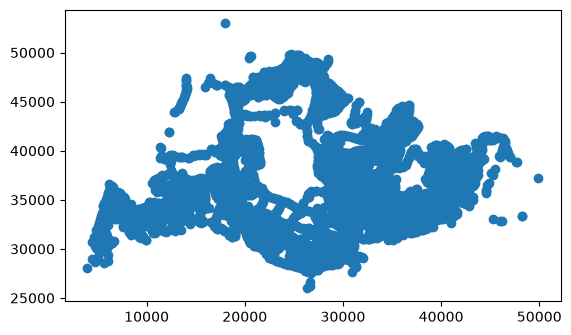

In [19]:
busstop.plot()

**Data wrangling**

There are some bus stops outside of the main island (i.e. in Malaysia) that will need to be filtered out using the Singapore boundary dataset I sourced in Section 1.

In [70]:
busstop_svy21 = busstop.to_crs(epsg=3414).copy()
sg_main_geom = sg_boundary.to_crs(epsg=3414).geometry.union_all()

# filter bus stops strictly within the singapore main island boundary (drops jb cross-border & offshore stops)
busstop_clean = busstop_svy21[busstop_svy21.geometry.within(sg_main_geom)].reset_index(drop=True)

print(f"raw bus stops: {len(busstop_svy21):,}")
print(f"removed (outside main island boundary): {len(busstop_svy21) - len(busstop_clean):,}")
print(f"bus stops within main island: {len(busstop_clean):,}")

raw bus stops: 5,205
removed (outside main island boundary): 8
bus stops within main island: 5,197


In [71]:
# save
busstop_clean.to_file("../../data/bus_stops_clean.geojson", driver="GeoJSON")

In [112]:
bus_wgs84 = busstop_clean.to_crs(epsg=4326).copy()
bus_wgs84["lon"] = bus_wgs84.geometry.x
bus_wgs84["lat"] = bus_wgs84.geometry.y

# initialize base map with prefer_canvas=True so 5,000+ bus stops render smoothly
m_bus = folium.Map(
    location=[1.3521, 103.8198],
    zoom_start=11.5,
    tiles=None,
    prefer_canvas=True,
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, © OpenStreetMap contributors, and the GIS User Community",
    name="Esri Dark Gray Base",
).add_to(m_bus)

# add mainland singapore boundary in the background
folium.GeoJson(
    sg_boundary.to_crs(epsg=4326),
    name="Singapore Boundary",
    style_function=lambda x: {
        "fillColor": "#94a3b8",
        "color": "#64748b",
        "weight": 1.2,
        "fillOpacity": 0.12,
    },
).add_to(m_bus)

# plot filtered bus stops with BUS_STOP_N and LOC_DESC in the hover tooltip
for _, row in bus_wgs84.iterrows():
    tooltip_html = f"<b>Bus Stop {row['BUS_STOP_N']}</b><br>{row['LOC_DESC']}"

    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=2.5,
        color="#34d399",
        weight=0.5,
        fill=True,
        fill_color="#34d399",
        fill_opacity=0.75,
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(m_bus)

# floating header box with data source
header_html = f"""
<div style="position: fixed; top: 15px; left: 55px; z-index: 9999; background: rgba(15, 23, 42, 0.9);
            color: #f8fafc; padding: 10px 16px; border: 1px solid #334155; border-radius: 8px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <div style="font-size: 16px; font-weight: 700; margin-bottom: 2px;">
    Singapore Main Island Bus Stops (n = {len(bus_wgs84):,})
  </div>
  <div style="font-size: 12px; color: #cbd5e1;">
    Zoom in and hover over any stop to inspect bus stop code and location
  </div>
  <div style="font-size: 11px; color: #94a3b8; margin-top: 2px;">
    Source: LTA DataMall
  </div>
</div>
"""
m_bus.get_root().html.add_child(folium.Element(header_html))

# legend in bottom-right corner
legend_html = """
<div style="position: absolute; bottom: 30px; right: 30px; z-index: 9999; background: rgba(15, 23, 42, 0.92);
            color: #f8fafc; padding: 10px 14px; border: 1px solid #334155; border-radius: 8px; font-size: 13px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <b>Bus Infrastructure</b><br>
  <span style="color:#34d399;">●</span> Public Bus Stop
</div>
"""
m_bus.get_root().html.add_child(folium.Element(legend_html))

m_bus

## 2c. Load point data of MRT stations
The data was sourced from [LTA Datamall](https://datamall.lta.gov.sg/content/datamall/en/static-data.html). The shapefile was downloaded directly into the repository.

<Axes: >

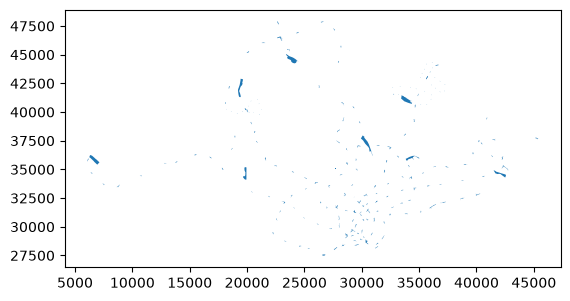

In [18]:
mrt.plot()

**Troubleshooting**

Upon pre-investigation in QGIS, the MRT dataset are polygons and contain repeated entries of the interchange stations with multiple lines/station codes. For example, Bugis interchange station (DT14/EW12) is part of both the Downtown (DT) line and East-West (EW) line and have two polygons drawn adjacent to each other. To convert this into simplified point data, the touching polygons will be merged into one, and the centroid of the final polygons are taken as the location of the MRT station.

In [20]:
print("columns in mrt shapefile:", mrt.columns.tolist())
print(f"raw polygon count: {len(mrt)}")

columns in mrt shapefile: ['JOB_NUM', 'TYP_CD', 'STN_NAM', 'EXCEPTION_', 'LAST_UPD_U', 'LAST_UPD_D', 'CRT_USRID_', 'CRT_DTTM', 'RTS_LVL_NU', 'LIN_NAM', 'PKG_REF', 'REMARKS', 'ATTACHEMEN', 'SHAPE_AREA', 'SHAPE_LEN', 'geometry']
raw polygon count: 234


In [21]:
mrt.head(5)

,JOB_NUM,TYP_CD,STN_NAM,EXCEPTION_,LAST_UPD_U,LAST_UPD_D,CRT_USRID_,CRT_DTTM,RTS_LVL_NU,LIN_NAM,PKG_REF,REMARKS,ATTACHEMEN,SHAPE_AREA,SHAPE_LEN,geometry
0,GDMDM20190314-025,33,PE3,None,SAID,2019-03-14,RATINAR,2005-06-24,3,PLRT,None,None,NaN,1054.611639,170.560957,"POLYGON ((36786.934 41775.313, 36787.145 41775..."
1,GDMDM20190314-025,34,EW5,None,SAID,2019-03-14,system,2004-10-27,3,EWL,None,None,NaN,4710.645797,384.785954,"POLYGON ((38705.801 34003.199, 38702.824 34003..."
2,GDMDM20190314-025,33,PTC,None,SAID,2019-03-14,RATINAR,2005-06-24,3,PLRT,None,None,NaN,11506.503525,648.115862,"POLYGON ((35714.661 43007.042, 35713.307 43004..."
3,GDMDM20170713-002,34,DT33,None,RATINAR,2017-07-13,RATINAR,2017-07-13,1,DTL,None,None,NaN,10262.523191,990.521390,"POLYGON ((41625.465 37668.568, 41625.439 37651..."
4,LTAGDMDM20090430-019,33,PW7,None,RATINAR,2009-04-30,RATINAR,2005-06-24,3,PLRT,None,None,NaN,1050.088313,170.457811,"POLYGON ((35110.205 42970.713, 35108.107 42971..."


In [116]:
# merge touching/adjacent interchange polygons using a tiny 1m buffer then explode into single parts
merged_geom = mrt.geometry.buffer(1).union_all()
merged_gdf = (
    gpd.GeoDataFrame(geometry=[merged_geom], crs="EPSG:3414")
    .explode(index_parts=False)
    .reset_index(drop=True)
)
merged_gdf["merged_id"] = merged_gdf.index

# spatial join original attributes back onto the merged polygons so interchange codes & lines are kept
joined = gpd.sjoin(mrt, merged_gdf, how="inner", predicate="intersects")

# group by merged polygon and combine station codes (e.g. DT14 / EW12) and line names
station_attrs = joined.groupby("merged_id", as_index=False).agg(
    station_code=("STN_NAM", lambda s: " / ".join(sorted(set(s.dropna().astype(str).str.strip())))),
    line_name=("LIN_NAM", lambda s: " / ".join(sorted(set(s.dropna().astype(str).str.strip())))),
    typ_cd=("TYP_CD", lambda s: " / ".join(sorted(set(s.dropna().astype(str).str.strip())))),
)

# attach attributes back to the merged polygons and take the centroid as the simplified point
mrt_stations = merged_gdf.merge(station_attrs, on="merged_id", how="left").drop(columns=["merged_id"])
mrt_stations["geometry"] = mrt_stations.geometry.centroid

print(f"simplified unique mrt station points: {len(mrt_stations)}")

# preview merged interchange stations (rows with "/" in station_code) to verify they combined properly
interchanges = mrt_stations[mrt_stations["station_code"].str.contains("/", na=False)]
print(f"interchange stations merged: {len(interchanges)}")
display(interchanges.head(50))

simplified unique mrt station points: 201
interchange stations merged: 25


,geometry,station_code,line_name,typ_cd
10,POINT (17866.632 35044.915),EW24 / NS1,EWNS,34
36,POINT (18105.103 40783.171),BP1 / NS4,BPLRT / NSL,33 / 34
43,POINT (22874.874 46448.737),NS9 / TE2,NSL / TEC,34
51,POINT (28666.78 29233.108),EW16 / NE3,EWL / NEL / TEC,34
61,POINT (23219.816 32121.592),CC22 / EW21,CCL / EWL,34
64,POINT (28525.192 32805.304),DT11 / NS21,DTL / NSL,34
67,POINT (26013.985 33830.871),CC19 / DT9,CCL / DTL,34
85,POINT (30411.739 28684.961),CE2 / NS27,CCL / NSL / TEC,34
90,POINT (30866.864 29368.471),DT16 / CE1,DTCC,34
92,POINT (30018.537 29608.376),EW14 / NS26,EWNS,34


**Data wrangling**

To merge the polygons at each interchange, a 1m buffer is first placed to ensure the adjacent polygons intersect each other, and then merged using predicate = "intersects". The station names STN_NAM for these interchanges with multiple intersecting lines are combined into a new column called "station_code". Same thing for station lines LIN_NAM into line_name.

---

**More troubleshooting**

There are 201 observations which is more than the number of MRT/LRT stations in Singapore. Further investigation through QGIS shows that there are some depots included in the list that are not accessible to the public. They will be removed by filtering out any observations where the station_code does not include a number (this means they are not part of an existing MRT line). We can see such stations below. They all have station codes that are indecipherable.

In [117]:
# remove depots
has_number = mrt_stations["station_code"].str.contains(r"\d", regex=True, na=False)
removed_depots = mrt_stations[~has_number].copy()
mrt_stations = mrt_stations[has_number].reset_index(drop=True)

print(f"depots removed: {len(removed_depots)}")
print(f"valid public mrt/lrt stations remaining: {len(mrt_stations)}")

# inspect removed depots to verify no passenger stations were dropped
display(removed_depots[["station_code", "line_name", "typ_cd"]])

depots removed: 11
valid public mrt/lrt stations remaining: 190


,station_code,line_name,typ_cd
8,UPD,EWL,34
14,TD,TWE,34
32,BPLD,BPLRT,33
39,GBD,DTL,34
78,MD,TEC,34
107,HSSCT,DTL,34
117,BD,NSL,34
140,KCD / TSCDTFB / TSFB,CCL / DTL,34
149,SLD / SMD,NEL / SLRT,33 / 34
167,CD,EWL,34


**Data wrangling**

There are 190 stations even though there are only 184 operational stations currently. Upon further investigation, I found out that this is because the dataset includes some reserved stations that are under construction/have not been opened yet (e.g. CC18 Bukit Brown, CC30 Keppel). The list of upcoming stations was verified by checking the [Upcoming Projects](https://www.lta.gov.sg/content/ltagov/en/upcoming_projects.html) webpage published by LTA:
1. CC18
2. CC30
3. CC31
4. CC32
5. TE21
6. TE22A

They will need to be removed to assess current accessibility for transit users.

In [118]:
# filter out unopened / reserved shell stations not open to the public
unopened_codes = {"CC18", "CC30", "CC31", "CC32", "TE21", "TE22A"}
removed_unopened = mrt_stations[mrt_stations["station_code"].isin(unopened_codes)].copy()
mrt_stations = mrt_stations[~mrt_stations["station_code"].isin(unopened_codes)].reset_index(drop=True)

print(f"unopened/shell stations removed: {len(removed_unopened)}")
print(f"operational public mrt/lrt stations remaining: {len(mrt_stations)}")
display(removed_unopened[["station_code", "line_name", "typ_cd"]])

# overwrite geojson with the 184 operational stations
mrt_stations.to_file("../../data/mrt_stations_clean.geojson", driver="GeoJSON")

unopened/shell stations removed: 6
operational public mrt/lrt stations remaining: 184


,station_code,line_name,typ_cd
42,CC30,CCL,34
45,CC31,CCL,34
67,CC18,CCL,34
79,CC32,CCL,34
114,TE21,TEC,34
116,TE22A,TEC,34


In [119]:
import folium

# reproject cleaned operational stations to wgs84 (epsg:4326) for folium
all_stations_wgs84 = mrt_stations.to_crs(epsg=4326).copy()
all_stations_wgs84["lon"] = all_stations_wgs84.geometry.x
all_stations_wgs84["lat"] = all_stations_wgs84.geometry.y

# official LTA line colors (including branch/extension codes TWE & CA under EWL)
lta_line_colors = {
    "NSL": "#D42E12",   # North-South Line (Red)
    "EWL": "#009645",   # East-West Line (Green)
    "TWE": "#009645",   # Tuas West Extension (EWL Green)
    "CA": "#009645",    # Changi Airport Branch (EWL Green)
    "NEL": "#9900AA",   # North East Line (Purple)
    "CCL": "#FA9E0D",   # Circle Line (Orange)
    "DTL": "#005EC4",   # Downtown Line (Blue)
    "TEC": "#9D5B25",   # Thomson-East Coast Line (Brown)
    "BPLRT": "#748477", # Bukit Panjang LRT (Grey)
    "SLRT": "#748477",  # Sengkang LRT (Grey)
    "PLRT": "#748477",  # Punggol LRT (Grey)
}
interchange_color = "#FFFFFF"  # Crisp white to stand out against all LTA line colors on dark basemap

def get_station_style(row):
    code = str(row["station_code"])
    line = str(row["line_name"])
    is_interchange = ("/" in code) or ("/" in line) or (line in {"EWNS", "DTCC"})
    if is_interchange:
        return interchange_color, True
    return lta_line_colors.get(line, "#94a3b8"), False

# initialize base map centered on singapore with esri dark gray base tiles
m_all_stations = folium.Map(location=[1.3521, 103.8198], zoom_start=11.5, tiles=None)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, © OpenStreetMap contributors, and the GIS User Community",
    name="Esri Dark Gray Base",
).add_to(m_all_stations)

# add mainland singapore boundary in the background
folium.GeoJson(
    sg_boundary.to_crs(epsg=4326),
    name="Singapore Boundary",
    style_function=lambda x: {
        "fillColor": "#94a3b8",
        "color": "#64748b",
        "weight": 1.2,
        "fillOpacity": 0.12,
    },
).add_to(m_all_stations)

# plot single-line stations first, then interchanges on top so interchanges remain clearly visible
single_rows = []
interchange_rows = []
for _, row in all_stations_wgs84.iterrows():
    color, is_interchange = get_station_style(row)
    if is_interchange:
        interchange_rows.append((row, color))
    else:
        single_rows.append((row, color))

for row, color in single_rows:
    tooltip_html = (
        f"<b>{row['station_code']}</b><br>"
        f"Line: {row['line_name']}<br>"
        f"Type: Single-Line Station"
    )
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=4.5,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.9,
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(m_all_stations)

for row, color in interchange_rows:
    tooltip_html = (
        f"<b>{row['station_code']}</b><br>"
        f"Lines: {row['line_name']}<br>"
        f"Type: Interchange Station"
    )
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=6,
        color="#0f172a",
        weight=1.5,
        fill=True,
        fill_color=color,
        fill_opacity=0.95,
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(m_all_stations)

# floating header box with data source
header_html = f"""
<div style="position: fixed; top: 15px; left: 55px; z-index: 9999; background: rgba(15, 23, 42, 0.9);
            color: #f8fafc; padding: 10px 16px; border: 1px solid #334155; border-radius: 8px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <div style="font-size: 16px; font-weight: 700; margin-bottom: 2px;">
    Operational Singapore MRT & LRT Stations (n = {len(all_stations_wgs84)})
  </div>
  <div style="font-size: 12px; color: #cbd5e1;">
    Hover over any station for codes and lines
  </div>
  <div style="font-size: 11px; color: #94a3b8; margin-top: 2px;">
    Source: LTA DataMall
  </div>
</div>
"""
m_all_stations.get_root().html.add_child(folium.Element(header_html))

# legend in bottom-right corner with official LTA colors + interchanges
legend_html = """
<div style="position: fixed; bottom: 30px; right: 30px; z-index: 9999; background: rgba(15, 23, 42, 0.92);
            color: #f8fafc; padding: 12px 16px; border: 1px solid #334155; border-radius: 8px; font-size: 12.5px;
            line-height: 1.6; box-shadow: 0 2px 6px rgba(0,0,0,0.4);">
  <div style="font-weight: 700; margin-bottom: 4px; font-size: 13px;">LTA Rail Lines</div>
  <span style="color:#FFFFFF;">●</span> Interchange Station<br>
  <span style="color:#D42E12;">●</span> North-South Line (NSL)<br>
  <span style="color:#009645;">●</span> East-West Line (EWL)<br>
  <span style="color:#9900AA;">●</span> North East Line (NEL)<br>
  <span style="color:#FA9E0D;">●</span> Circle Line (CCL)<br>
  <span style="color:#005EC4;">●</span> Downtown Line (DTL)<br>
  <span style="color:#9D5B25;">●</span> Thomson-East Coast Line (TEL)<br>
  <span style="color:#748477;">●</span> LRT (BP / SK / PG)
</div>
"""
m_all_stations.get_root().html.add_child(folium.Element(legend_html))

m_all_stations

## 3. Network analysis using OSMnx
I performed a network analysis from nightlife venues to the nearest MRT station/bus stop to compute the average walking distance to the nearest transit stop. This is to map the accessibility of transit from nightlife venues.

## 3a. Retrieving walking network from OSM
The walking network will be retrieved only for a 1,500m buffer around each nightlife venue to prevent overloading Overpass.

The network was retrieved from [BBBike](https://download.bbbike.org/osm/bbbike/Singapore/), a website providing free OSM extracts.

In [83]:
nightlife_wgs84 = gpd.read_file("../../data/singapore_nightlife_ssic.geojson")

In [77]:
type(sg_boundary)
sg_boundary_polygon = sg_boundary.geometry.iloc[0]

In [91]:
venues_svy21 = nightlife_wgs84.to_crs(epsg=3414)
sg_main_geom = sg_boundary.to_crs(epsg=3414).geometry.union_all()

study_union = (
    venues_svy21.geometry.buffer(1000)
    .union_all()
    .intersection(sg_main_geom)
    .simplify(50)
)

# explode into separate cluster polygons and convert to wgs84 (epsg:4326)
clusters_gdf = (
    gpd.GeoDataFrame(geometry=[study_union], crs="EPSG:3414")
    .explode(index_parts=False)
    .reset_index(drop=True)
    .to_crs(epsg=4326)
)

print(f"Total disconnected nightlife clusters to query: {len(clusters_gdf)}")

Total disconnected nightlife clusters to query: 22


In [98]:
#!pip install osmium
import osmium as osm

src = "../../data/Singapore.osm.gz"
hw_out = "../../data/highways.osm"
transit_out = "../../data/transit.osm"

# highways: way + node ids
way_ids, node_ids = set(), set()
for o in osm.FileProcessor(src, osm.osm.WAY):
    if "highway" in o.tags:
        way_ids.add(o.id)
        node_ids.update(n.ref for n in o.nodes)

with osm.SimpleWriter(hw_out) as w:
    for o in osm.FileProcessor(src, osm.osm.NODE | osm.osm.WAY):
        if o.is_node() and o.id in node_ids:
            w.add_node(o)
        elif o.is_way() and o.id in way_ids:
            w.add_way(o)

# transit stops (nodes only)
with osm.SimpleWriter(transit_out) as w:
    for o in osm.FileProcessor(src, osm.osm.NODE):
        t = o.tags
        if (t.get("highway") == "bus_stop"
                or t.get("railway") in ("station", "subway_entrance")):
            w.add_node(o)

In [99]:
for p in (hw_out, transit_out):
    print(p, f"{os.path.getsize(p)/1e6:.1f} MB")

../../data/highways.osm 265.2 MB
../../data/transit.osm 3.4 MB


**Data wrangling**

Now that the osm file has been downloaded, a NetworkX MultiDiGraph can be created. Only walkable network will be kept by filtering out vehicular values in OSM such as "motorway" and "construction".

In [102]:
graph_path = "../../data/nightlife_walk.graphml"
hw_out = "../../data/highways.osm"

if os.path.exists(graph_path) and os.path.getsize(graph_path) > 0:
    G_walk = ox.load_graphml(graph_path)
else:
    if os.path.exists(graph_path):
        os.remove(graph_path)

    # Load compact highways.osm locally
    G_hw = ox.graph_from_xml(hw_out, bidirectional=True, simplify=True)

    # keep only walkable ways (exclude expressways/motorways & restricted paths)
    non_walk = {
        "motorway", "motorway_link", "trunk", "trunk_link",
        "busway", "raceway", "proposed", "construction"
    }
    remove_edges = []
    for u, v, k, data in G_hw.edges(keys=True, data=True):
        hw = data.get("highway")
        hw_set = set(hw) if isinstance(hw, list) else {hw}
        if (hw_set & non_walk) or data.get("foot") == "no" or data.get("access") == "private":
            remove_edges.append((u, v, k))
    G_hw.remove_edges_from(remove_edges)

    # clip to buffered nightlife clusters and save to disk
    study_poly_wgs84 = clusters_gdf.geometry.union_all()
    G_walk = ox.truncate.truncate_graph_polygon(G_hw, study_poly_wgs84, truncate_by_edge=True)
    ox.save_graphml(G_walk, graph_path)

# reproject to SVY21 (EPSG:3414) so edge lengths are in meters
G_proj = ox.project_graph(G_walk, to_crs="EPSG:3414")
print(f"Walkable Graph Ready — Nodes: {len(G_proj.nodes):,} | Edges: {len(G_proj.edges):,}")

Walkable Graph Ready — Nodes: 121,091 | Edges: 330,354


## 3b. Network analysis, aggregated
I now describe the summary statistics for the walking distance from nightlife venues to the nearest transit node. This will be done by snapping the nightlife points to the nearest network node, and then computing the distance from this snapped point to the nearest MRT/bus station.

In [103]:
# load cleaned layers in SVY21 (EPSG:3414)
venues_svy21 = nightlife_wgs84.to_crs(epsg=3414).copy()
mrt_svy21 = gpd.read_file("../../data/mrt_stations_clean.geojson").to_crs(epsg=3414)
bus_svy21 = gpd.read_file("../../data/bus_stops_clean.geojson").to_crs(epsg=3414)

# snap points to nearest pedestrian network nodes (with snap distance to check coverage)
venues_svy21["osmid"], venues_svy21["snap_dist_m"] = ox.nearest_nodes(
    G_proj, venues_svy21.geometry.x, venues_svy21.geometry.y, return_dist=True
)
mrt_nodes = set(ox.nearest_nodes(G_proj, mrt_svy21.geometry.x, mrt_svy21.geometry.y))
bus_nodes = set(ox.nearest_nodes(G_proj, bus_svy21.geometry.x, bus_svy21.geometry.y))

# reverse graph so Dijkstra computes distance from every node --> nearest transit stop
G_rev = G_proj.reverse(copy=False)

dist_to_mrt = nx.multi_source_dijkstra_path_length(G_rev, sources=mrt_nodes, weight="length")
dist_to_bus = nx.multi_source_dijkstra_path_length(G_rev, sources=bus_nodes, weight="length")

# map walking distances (in meters) onto nightlife venues
venues_svy21["walk_dist_mrt_m"] = venues_svy21["osmid"].map(dist_to_mrt)
venues_svy21["walk_dist_bus_m"] = venues_svy21["osmid"].map(dist_to_bus)

print(f"Unreached MRT count (NaN): {venues_svy21['walk_dist_mrt_m'].isna().sum()}")
print(f"Unreached Bus count (NaN): {venues_svy21['walk_dist_bus_m'].isna().sum()}")
venues_svy21[["walk_dist_mrt_m", "walk_dist_bus_m", "snap_dist_m"]].describe()

Unreached MRT count (NaN): 11
Unreached Bus count (NaN): 5


,walk_dist_mrt_m,walk_dist_bus_m,snap_dist_m
count,609.000000,615.000000,620.000000
mean,491.258614,167.069110,24.203944
std,336.447141,126.663366,12.522404
min,0.000000,0.000000,0.000000
25%,290.129614,92.045231,15.127642
50%,412.158223,141.003034,21.480291
75%,549.762209,226.782756,31.397670
max,2720.727950,1455.008271,78.875467


Overall, the average walking distance to an MRT is 491min, which is about 6mins. That of buses is 126m, which is about 2min and very close by! It is similar to the Land Transport Authority target for amenities to be within a 400m radius to MRTs and 200m radius to bus stops, which indicates good connectivity.

The snapped distance shows that the network analysis is a generally good proxy for walking distance, with the snap distance ranging from 0 to 78m which is quite a negligible difference between the actual point location and the snapped location. A larger snap distance probably indicates that the venue is located within a large mall/venue that is quite far away from the nearest network node.

There are 11 nightlife venues displaying an unreached MRT count, and 5 venues displaying an unreached bus count. This means that they are beyond the 1000m geometry.buffer from the nearest transit station. The buffer should have been expanded slightly to account for this but for computational efficiency the 1000m buffer is kept. However, it does indicate that there are some venues quite inaccessibly by public transport (>1km away).

## 3c. Network analysis per venue

In [121]:
import folium
import pandas as pd

# 1. reproject venues to wgs84 (epsg:4326) for folium
venues_wgs84 = venues_svy21.to_crs(epsg=4326).copy()
venues_wgs84["lon"] = venues_wgs84.geometry.x
venues_wgs84["lat"] = venues_wgs84.geometry.y

# Define distance color palette (green = close, yellow/orange = moderate, red = far)
palette = {
    "< 200 m": "#10b981",      # emerald
    "200 – 400 m": "#facc15",  # yellow
    "400 – 800 m": "#f97316",  # orange
    "> 800 m": "#ef4444",      # red
    "No data": "#64748b",      # slate gray (for NaN / > buffer)
}

def assign_color(dist):
    if pd.isna(dist):
        return palette["No data"]
    if dist < 200:
        return palette["< 200 m"]
    elif dist < 400:
        return palette["200 – 400 m"]
    elif dist < 800:
        return palette["400 – 800 m"]
    return palette["> 800 m"]

# dark basemap
m_venues = folium.Map(
    location=[1.315, 103.845],
    zoom_start=12,
    tiles=None,
    prefer_canvas=True,
)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Dark_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, © OpenStreetMap contributors, and the GIS User Community",
    name="Esri Dark Gray Base",
    control=False,
).add_to(m_venues)

folium.GeoJson(
    sg_boundary.to_crs(epsg=4326),
    name="Singapore Boundary",
    style_function=lambda x: {
        "fillColor": "#94a3b8",
        "color": "#475569",
        "weight": 1.0,
        "fillOpacity": 0.08,
    },
).add_to(m_venues)

# Create two toggleable point layers for mrt and bus
fg_mrt = folium.FeatureGroup(name="Walk Distance to Nearest MRT", show=True)
fg_bus = folium.FeatureGroup(name="Walk Distance to Nearest Bus Stop", show=False)

for _, row in venues_wgs84.iterrows():
    mrt_str = f"{row['walk_dist_mrt_m']:.0f} m" if pd.notna(row["walk_dist_mrt_m"]) else "> Buffer (N/A)"
    bus_str = f"{row['walk_dist_bus_m']:.0f} m" if pd.notna(row["walk_dist_bus_m"]) else "> Buffer (N/A)"
    venue_name = row.get("NAME", row.get("name", "Nightlife Venue"))

    tooltip_html = (
        f"<b>{venue_name}</b><br>"
        f"Nearest MRT: <b>{mrt_str}</b><br>"
        f"Nearest Bus: <b>{bus_str}</b>"
    )

    # MRT layer point
    mrt_color = assign_color(row["walk_dist_mrt_m"])
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=4.5,
        color=mrt_color,
        weight=0.8,
        fill=True,
        fill_color=mrt_color,
        fill_opacity=0.85,
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(fg_mrt)

    # Bus layer point
    bus_color = assign_color(row["walk_dist_bus_m"])
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=4.5,
        color=bus_color,
        weight=0.8,
        fill=True,
        fill_color=bus_color,
        fill_opacity=0.85,
        tooltip=folium.Tooltip(tooltip_html),
    ).add_to(fg_bus)

fg_mrt.add_to(m_venues)
fg_bus.add_to(m_venues)

# layer switcher in top-right
folium.LayerControl(position="bottomright", collapsed=False).add_to(m_venues)

# floating title & bottom-right legend
header_html = f"""
<div style="position: absolute; top: 15px; left: 55px; z-index: 9999; background: rgba(15, 23, 42, 0.9);
            color: #f8fafc; padding: 10px 16px; border: 1px solid #334155; border-radius: 8px;
            box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <div style="font-size: 16px; font-weight: 700; margin-bottom: 2px;">
    Nightlife Venue Walking Distance to Public Transit (n = {len(venues_wgs84):,})
  </div>
  <div style="font-size: 12px; color: #cbd5e1;">
    Use top-right control to toggle MRT vs. Bus walking distance; hover over points for exact meters
  </div>
</div>
"""
m_venues.get_root().html.add_child(folium.Element(header_html))

legend_html = """
<div style="position: absolute; bottom: 30px; left: 30px; z-index: 9999; background: rgba(15, 23, 42, 0.92);
            color: #f8fafc; padding: 10px 14px; border: 1px solid #334155; border-radius: 8px; font-size: 13px;
            line-height: 1.6; box-shadow: 0 2px 6px rgba(0,0,0,0.4); pointer-events: none;">
  <b>Walking Distance</b><br>
  <span style="color:#10b981;">●</span> < 200 m (~2–3 min)<br>
  <span style="color:#facc15;">●</span> 200 – 400 m (~3–5 min)<br>
  <span style="color:#f97316;">●</span> 400 – 800 m (~5–10 min)<br>
  <span style="color:#ef4444;">●</span> > 800 m (> 10 min)<br>
  <span style="color:#64748b;">●</span> Beyond buffer / No data
</div>
"""
m_venues.get_root().html.add_child(folium.Element(legend_html))

m_venues

**The legend can be toggled with to see the walking distance from each nightlife venue to the nearest MRT/bus stop.**

### MRT stops

The map reveals transport deserts along Joo Chiat Rd and Balestier Road. These areas lie mid-way between major MRT lines, and face walks exceeding 800m. This creates a high risk of missing the last train around midnight.

- Policy recommendation: Rather than relying on costly rail infrasturcture changes, LTA could explore introduces extended-hour feeder bus servies along these nightlife corridors to link patrons to larger interchanges, and also increase designated ride-hailing/ride-share bays in these areas.

### Bus stops

Bus coverage is strong, with majority of venues within 200m of a bus stop. There are a few red/grey spots indicating pockets of lower/inaccessibility that fall into three categories that do not actually warrant immediate bus route expansion:

1. **Special hubs:**
- Changi Airport, a large airport with multiple terminals, and hence has only several designated public transport nodes. There are other forms of connections between the terminals (a.k.a. airport shuttle) that are not included in this dataset.

2. **Disconnected OSM networks**:
- There are several grey points located adjacent to green points, highlighting probably graph-snapping errors resulting in a false low accessibility report.
- There are several red points located inside Marina Bay Sands. Despite the presence of Bayfront MRT Station located inside the mall, these longer calculated distances are likely due to indoor/underground pedestrian linkways not accounted for in the OSM network.

3. **Intentional zoning**:
- Tiger Tavern: Tuas, a sprawling industrial hub with low pedestrian foot traffic and hence low public transport demand, catering more towards large freight trucks. It is surprising that there is a pub there - but further investigation shows that it used to be a tasting bar for the Tiger Beer Brewery tour, located within the brewery complex, which justifies why it is in an industrial area (now it is closed, though).
- Chang Chewang: Mandai Nature Reserve is a protected nature reserve where low transit accessibility is intentional.


---
Our exploration highlights the accessibility of nightlife venues to public transport nodes, which indicates generally good accessibility. However beyond spatial accessibility, their temporal accessibility is limited due to MRT/bus closure times.

In Section 3, I will examine where nightlife patrons are going (using Origin-Destination datasets) and how they can be better served at night.

In [110]:
# for further analysis in section 3
# keep venues distance to nearest mrt/bus just in case
venues_svy21.to_file("../../data/nightlife_venues_walk.geojson", driver="GeoJSON")